# When exactly ten of forty retinal neurons fire

A reanalysis of the public recordings behind Figure 5B of Tkačik, Marre, Amodei and colleagues (2014). We predict the number of 20 ms windows with exactly ten active neurons. Each neuron counts once in a window, even if it spiked twice. The published panel is digitized independently of the new fits. The authors’ public release contains all 160 cells. Identities of the particular 40 in the panel are unreported.

[Journal article and equations](https://doi.org/10.1371/journal.pcbi.1003408) · [Figure 5](https://doi.org/10.1371/journal.pcbi.1003408.g005) · [Original CC0 data and documentation](https://research-explorer.ista.ac.at/record/5562) · [Frozen group selection](protocol.json)

Open this notebook from the unzipped bundle. Running all cells with the default setting recomputes the primary counts and both independent forecasts directly from the original data, checks the supplied fits, and regenerates the figures. Set `REFIT = True` to fit the five models again. A full run uses a C++17 compiler.

In [1]:
from pathlib import Path
import csv, hashlib, json, subprocess, sys
import numpy as np
from IPython.display import display, HTML, Image

ROOT = Path.cwd()
assert (ROOT / 'protocol.json').is_file(), 'Open the notebook in the unzipped project directory.'
sys.path.insert(0, str(ROOT / 'code'))
from reproduce import prepare_data, time_split
from summarize import endpoint_table, plot_primary

protocol_path = ROOT / 'protocol.json'
assert hashlib.sha256(protocol_path.read_bytes()).hexdigest() == 'e6c442f56f95e1913cb05b204ab70ed5ba549d0b8da6ca5e0dea186eeef2b87b'
protocol = json.loads(protocol_path.read_text())
RESULTS = ROOT / 'results'
REFIT = False
if REFIT:
    subprocess.run([sys.executable, 'code/reproduce.py', '--mode', 'all', '--jobs', '2'], check=True)
print('Target:', protocol['target'])
print('Fit groups:', protocol['pairwise_groups_one_based'], 'of', len(protocol['groups_zero_based']))

Target: Exactly 10 of 40 neurons fire at least once in a 20-millisecond bin.
Fit groups: [1, 2, 3, 4, 5] of 30


## Count the bursts before fitting anything

The 297 repeats all show the same 19-second movie. We hold out every third repeat and keep all 953 consecutive windows of each repeat together. The 30 cell groups were fixed using seed 20261119. Group 1 is the primary analysis. Group sizes and evaluation choices are in the protocol file.

In [2]:
cube = np.load(prepare_data(ROOT / '.cache'), mmap_mode='r')
train, test = time_split(cube, 1)
counts = test.sum(axis=2)
windows = counts.size
events = int((counts == 10).sum())
print('Release shape (repeats, cells, bins):', cube.shape)
print(f'Train: {len(train)} repeats. Test: {len(test)} repeats, {windows:,} windows.')
print(f'Exactly 10 active cells in {events} windows, or {1000*events/windows:.3f} per 1,000.')

Release shape (repeats, cells, bins): (297, 160, 953)
Train: 198 repeats. Test: 99 repeats, 94,347 windows.
Exactly 10 active cells in 57 windows, or 0.604 per 1,000.


## Two ways to predict with independent cells

For fixed cell probabilities $p_i$, the coefficient of $z^{10}$ in $\prod_i(1-p_i+p_i z)$ gives the chance of ten active cells. The convolution below works even when different neurons have different rates. First average over the movie for each cell. Then let each cell have a separate rate at each of the 953 moments in the movie, estimated exclusively from the training repeats. Average those 953 probabilities to predict the test repeats. This second model has access to stimulus timing and uses 40 × 953 rate estimates per group.

In [3]:
def ten_cell_probability(probs):
    coefficients = np.array([1.])
    for p in probs:
        coefficients = np.convolve(coefficients, [1-p, p])
    return coefficients[10]

movie_rates = train.mean(axis=0)
constant_prob = ten_cell_probability(movie_rates.mean(axis=0))
movie_prob = np.mean([ten_cell_probability(p) for p in movie_rates])
print(f'Independent with constant rates: {constant_prob*windows:.4f} expected bursts.')
print(f'Independent given movie time:   {movie_prob*windows:.2f} expected bursts.')
print(f'Observed / constant-rate prediction: {events/(windows*constant_prob):,.0f}×.')

Independent with constant rates: 0.0478 expected bursts.
Independent given movie time:   55.87 expected bursts.
Observed / constant-rate prediction: 1,193×.


## Fit single cells and pairs, then predict ten

The model assigns probability $P(s)=Z^{-1}\exp(\sum_i h_i s_i+\sum_{i<j}J_{ij}s_i s_j)$. Its 40 single-cell terms and 780 pair terms are fitted to training statistics. The ten-cell endpoint is excluded from fitting. Symmetric pseudolikelihood initializes the fit. A training-only calibration of total pair coincidences and successive Monte Carlo updates refine the same 820 parameters. The original authors used a different numerical fitting procedure.

Four separate replica-exchange runs simulate each final model, with one million retained cold-chain states per group. `MC SE` estimates simulation error at fixed parameters. The observed interval resamples all the windows of each held-out movie repeat together. Neither covers differences between animals or new movies.

In [4]:
rows = endpoint_table()
primary = rows[0]
assert primary['observed_events'] == events
assert np.isclose(primary['independent_per_1000'], 1000*constant_prob, rtol=1e-11, atol=0)
assert np.isclose(primary['movie_conditioned_per_1000'], 1000*movie_prob, rtol=1e-11, atol=0)

labels = ['Group','Recorded windows','Observed [95% interval]','Independent','Pairwise ± MC SE','Movie-timed','Pairwise / observed']
fmt_rows = []
for r in rows[:5]:
    fmt_rows.append([str(r['group']),str(r['observed_events']),
       f"{r['observed_per_1000']:.3f} [{r['observed_ci_low_per_1000']:.3f}, {r['observed_ci_high_per_1000']:.3f}]",
       f"{r['independent_per_1000']:.6f}",f"{r['pairwise_per_1000']:.3f} ± {r['pairwise_mc_se_per_1000']:.3f}",
       f"{r['movie_conditioned_per_1000']:.3f}",f"{r['pairwise_over_observed']:.2f}×"])
def show_table(headers, values):
    from html import escape
    def cells(tag, row):
        return '<tr>'+''.join(f'<{tag} style="padding:6px 9px;text-align:right">{escape(str(x))}</{tag}>' for x in row)+'</tr>'
    display(HTML('<table>'+cells('th',headers)+''.join(cells('td',r) for r in values)+'</table>'))
print('Rates are windows per 1,000. Recorded windows are counts out of 94,347.')
show_table(labels,fmt_rows)
factor = np.array([r['observed_over_independent'] for r in rows])
print(f'Independent underestimate over 30 groups: median {np.median(factor):,.0f}×, range {factor.min():,.0f}–{factor.max():,.0f}×.')
print('Movie-timed model has smaller absolute log error than pairwise in',sum(r['movie_conditioned_abs_log_error']<r['pairwise_abs_log_error'] for r in rows[:5]),'of 5 groups.')

Rates are windows per 1,000. Recorded windows are counts out of 94,347.


Group,Recorded windows,Observed [95% interval],Independent,Pairwise ± MC SE,Movie-timed,Pairwise / observed
1,57,"0.604 [0.445, 0.763]",0.000506,2.183 ± 0.047,0.592,3.61×
2,102,"1.081 [0.890, 1.272]",0.000520,1.859 ± 0.045,1.046,1.72×
3,26,"0.276 [0.170, 0.392]",0.000174,1.492 ± 0.041,0.231,5.41×
4,105,"1.113 [0.890, 1.346]",0.000873,2.352 ± 0.052,0.926,2.11×
5,196,"2.077 [1.802, 2.342]",0.000937,2.756 ± 0.056,1.964,1.33×


Independent underestimate over 30 groups: median 1,373×, range 686–5,622×.
Movie-timed model has smaller absolute log error than pairwise in 5 of 5 groups.


## The published panel and the fresh fit

The first chart redraws central curves from the authors’ artwork. At exactly ten cells, the independent curve is below 0.001 per 1,000 windows. **Whether the authors measured 10,000× for this particular group is unknown.** The paper reports that scale in its text. The second chart uses counts from held-out repeats of our preselected group. [Source figure](https://doi.org/10.1371/journal.pcbi.1003408.g005) · [Author artwork](https://arxiv.org/abs/1306.3061)

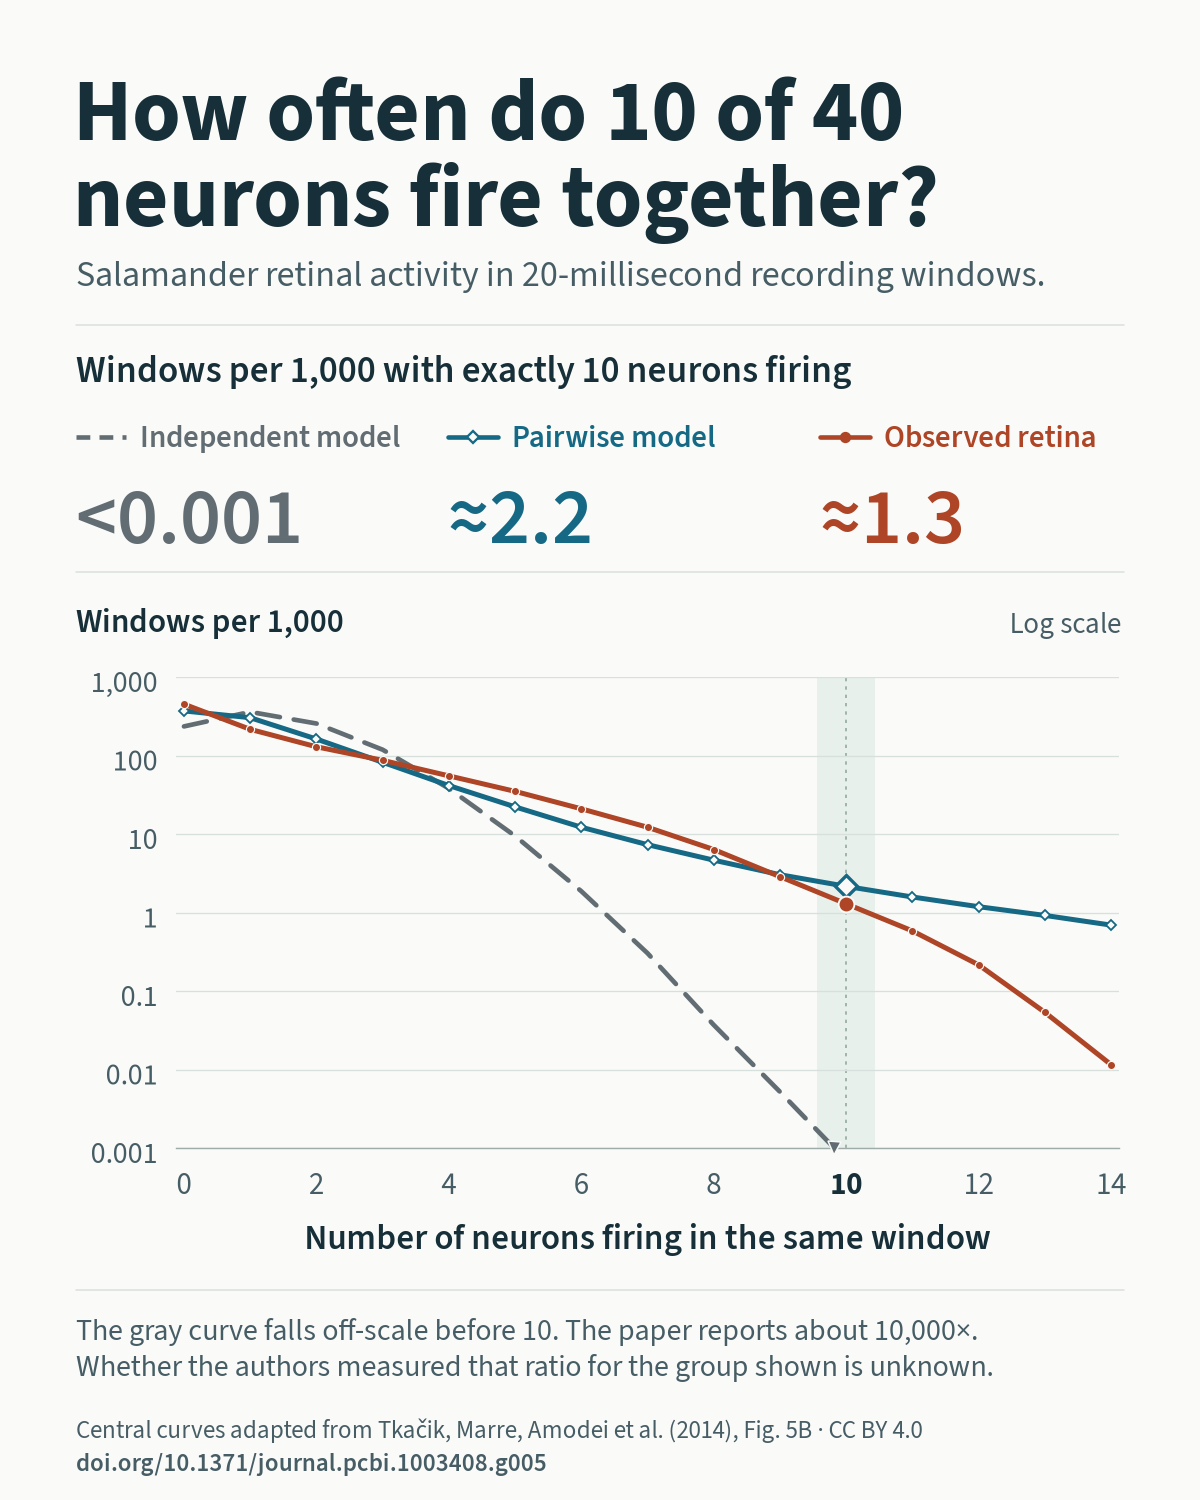

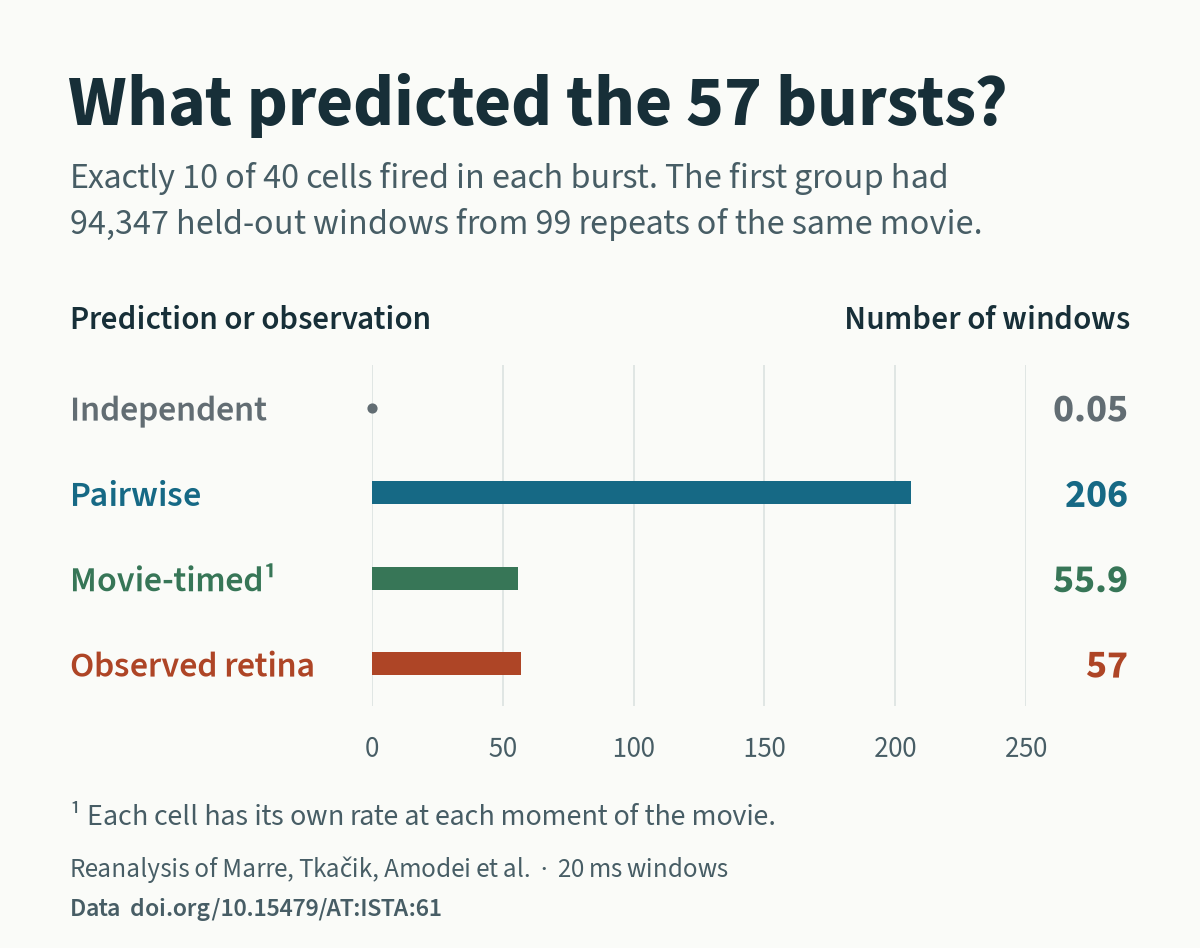

In [5]:
subprocess.run([sys.executable, 'code/figure5b.py'], check=True, capture_output=True)
plot_primary(primary)
display(Image(filename=str(ROOT/'figures/figure-5b-linkedin.png'),width=490))
display(Image(filename=str(ROOT/'figures/held-out-bursts.png'),width=600))

## Numerical checks and interpretation

A small eight-cell network can be enumerated exactly. We compare its count histogram and single/pair moments with the sampler, then compare the training single/pair moments with long independent simulations for every fitted 40-cell group. Compare the final rows with the target to see how well the numerical fit recovered its constraints. [All 30 groups](results/endpoint.csv) · [Figure readings and bound](results/figure5b-readout.json)

In [6]:
check=json.loads((RESULTS/'sampler-check.json').read_text())
print(f"8-cell check over all {check['exact_states']} states: max absolute count-probability error {check['max_abs_count_probability_error']:.5f}.")
quality=[]
for r in rows[:5]:
    group=r['group']; f=json.loads((RESULTS/f'pairwise-{group:02d}.json').read_text()); health=f['health']
    with np.load(RESULTS/f'weights-{group:02d}.npz') as saved:
        assert np.array_equal(saved['cells'],protocol['groups_zero_based'][group-1])
        assert np.allclose(saved['J'],saved['J'].T) and np.all(saved['J'].diagonal()==0)
        difference=saved['simulated_moments']-saved['train_moments']
        assert np.isclose(np.sqrt(np.mean(difference[40:]**2)),health['train_pair_rms'])
    quality.append([group,f"{health['train_single_rms']:.6f}",f"{health['train_pair_rms']:.6f}",
        f"{health['min_replica_swap_acceptance']:.2f}",', '.join(f'{1000*x:.3f}' for x in f['chain_k10'])])
show_table(['Group','Single RMS error','Pair RMS error','Minimum swap acceptance','4 simulated rates per 1,000'],quality)

8-cell check over all 256 states: max absolute count-probability error 0.00187.


Group,Single RMS error,Pair RMS error,Minimum swap acceptance,"4 simulated rates per 1,000"
1,0.000220,0.000074,0.26,"2.120, 2.144, 2.212, 2.256"
2,0.000214,0.000055,0.23,"1.816, 1.904, 1.884, 1.832"
3,0.000284,0.000087,0.16,"1.488, 1.464, 1.516, 1.500"
4,0.000230,0.000082,0.20,"2.200, 2.380, 2.420, 2.408"
5,0.000502,0.000131,0.26,"2.776, 2.820, 2.836, 2.592"


The stationary independent calculation underpredicts every group. Pairwise fitting recovers orders of magnitude on a multiplicative scale while still overpredicting this event in all five groups. A model with independent cells at each instant can also closely predict the aggregate frequency of ten-cell bursts when the movie is repeated. This endpoint does not distinguish shared visual input from direct circuit effects. The 30 groups overlap, and the results describe one recording. A stronger test would ask which ten cells fired or evaluate a stimulus-driven model on a new movie.

## Post-hoc split-size check

The paper used 277 training repeats and held out 20 for validation. How sensitive is the stationary independent-model comparison to using this split size? Keep the original 30 cell groups fixed, draw 100 sets of 20 test repeats, and refit the independent rates on each complement. The range below describes split-to-split variation in the **median across the 30 groups**. The splits overlap, and the authors’ actual cell and repeat IDs are unavailable in the public material. This check does not refit the pairwise models. [Published methods](https://doi.org/10.1371/journal.pcbi.1003408)

In [7]:
from check_repetition_split import check_splits
split_check = check_splits()
archived = json.loads((RESULTS / 'split-check.json').read_text())
np.testing.assert_allclose(split_check['split_medians'], archived['split_medians'])
low, high = split_check['range_of_split_medians']
print(f"100 splits of 277 training and 20 test repeats: median group ratios {low:,.0f}× to {high:,.0f}×.")
print(f"Median over splits: {split_check['median_of_split_medians']:,.0f}×.")
print(f"Across the full archive {split_check['proportion_occupied']:.2%} of cell-windows were active. The paper reports approximately 3.1%.")

100 splits of 277 training and 20 test repeats: median group ratios 1,124× to 1,748×.
Median over splits: 1,417×.
Across the full archive 3.58% of cell-windows were active. The paper reports approximately 3.1%.


## Could one read 10,000× from Figure 5B?

**Whether the authors measured 10,000× for these 40 neurons is unknown.** The released recording has 160 cells. The figure plots the retinal count and pairwise prediction at ten, but the gray prediction disappears below the scale before ten. Calculate where it crosses the axis and where it would cross if a straight segment connected the visible point at nine to the value required for 10,000×. Extending a line on a logarithmic axis is an estimate. The journal PDF and the authors’ press-ready figure encode the same artwork in two resolutions.

The two-PDF check downloads the original files when enabled and verifies their checksums. The stored measurements can be viewed offline. [Published PDF, page 7](https://journals.plos.org/ploscompbiol/article/file?id=10.1371/journal.pcbi.1003408&type=printable#page=7) · [Authors’ source](https://arxiv.org/abs/1306.3061)

In [8]:
RECHECK_SOURCE_PDFS = False
if RECHECK_SOURCE_PDFS:
    subprocess.run([sys.executable, 'code/figure_discrepancy.py'], check=True)
audit = json.loads((RESULTS/'figure-discrepancy.json').read_text())
assert audit['published_direct_gray_value_at_10'] is None
for source in ('journal_vector', 'author_vector'):
    v = audit[source]
    print(f"{source}: visible floor crossing at K={v['visible_gray_crosses_floor_at_k']:.2f}. "
          f"A straight segment to a 10,000× endpoint would cross at {v['crossing_k_if_10000_and_straight']:.2f}.")
    print(f"  Extending the visible segment gives {v['fold_if_segment_continues']:,.0f}× (graphical estimate).")
print('Whether 10,000× was measured for the plotted cells:', audit['did_authors_measure_10000_for_the_plotted_group'])

journal_vector: visible floor crossing at K=9.82. A straight segment to a 10,000× endpoint would cross at 9.45.
  Extending the visible segment gives 1,859× (graphical estimate).
author_vector: visible floor crossing at K=9.82. A straight segment to a 10,000× endpoint would cross at 9.45.
  Extending the visible segment gives 1,859× (graphical estimate).
Whether 10,000× was measured for the plotted cells: Unknown.


## How often does 10,000× occur in the released recording?

This post-hoc check fixes a seed and uniformly draws 10,000 groups of 40 cells before scoring them. Each group compares the observed frequency of **exactly** ten active cells with independence at the 40 individual rates. We evaluate both the full recording and the original 198/99 train/test partition. The full-recording analysis uses all 297 movie repeats for both rates. The proportions describe overlapping groups in a single retina. The threshold count uses ≥10,000, while the paper’s prose uses an approximate comparison. [Sample design](group-sensitivity-plan.json) · [Source recording](https://research-explorer.ista.ac.at/record/5562) · [Second deposit](https://doi.org/10.6084/m9.figshare.5009840.v2)

Full-recording exact 10: {'min': 98.49459195974055, 'p01': 353.21885900014246, 'p05': 535.1120001416458, 'p25': 943.1615215945735, 'median': 1463.4316013494627, 'p75': 2341.919931497822, 'p95': 4897.672069614405, 'p99': 8596.469020996212, 'max': 34897.87413249247}


Groups with ratios >= 10,000: 64 / 10000


All repeats: median 1,463×, middle half 943–2,342×. At least 10,000×: 64 of 10,000 groups (0.64%).
Held-out repeats: median 1,430×, middle half 918–2,307×. At least 10,000×: 55 of 10,000 groups (0.55%).


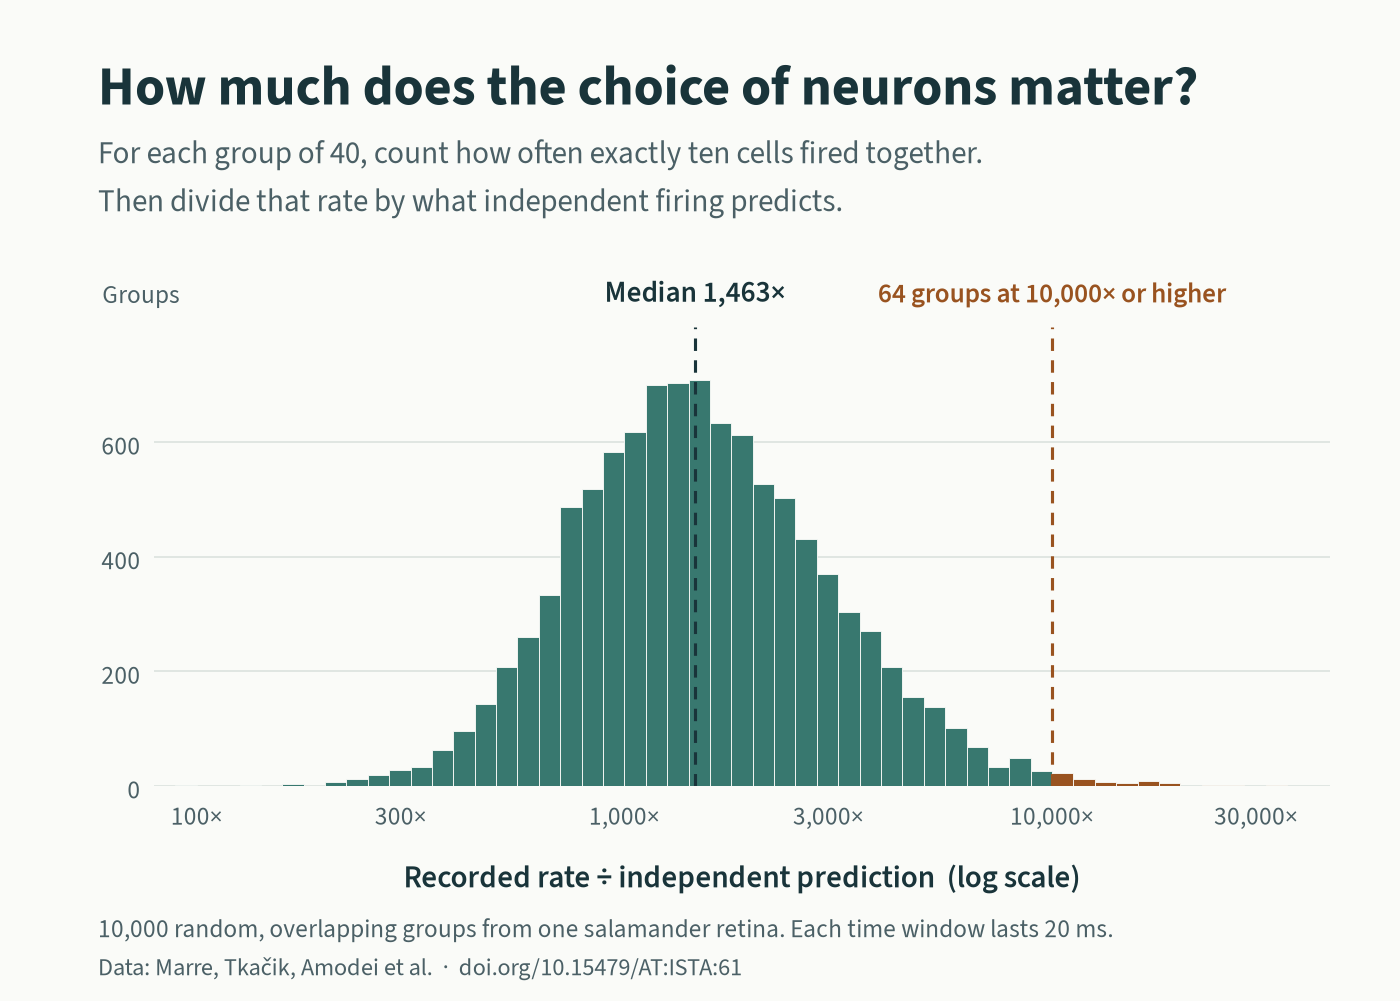

In [9]:
from group_sensitivity import main as compute_group_sensitivity
from plot_group_sensitivity import main as draw_group_sensitivity
compute_group_sensitivity()
sensitivity = json.loads((RESULTS/'group-sensitivity.json').read_text())
n = sensitivity['groups']
for label, summary, count in [
    ('All repeats', sensitivity['full_exact']['10'], sensitivity['full_groups_at_least_10000']),
    ('Held-out repeats', sensitivity['test_exact_10'], sensitivity['test_groups_at_least_10000'])
]:
    print(f"{label}: median {summary['median']:,.0f}×, middle half {summary['p25']:,.0f}–{summary['p75']:,.0f}×. "
          f"At least 10,000×: {count} of {n:,} groups ({count/n:.2%}).")
draw_group_sensitivity()
display(Image(filename=str(ROOT/'figures'/'group-sensitivity.png')))